# Introduction
UMAP visualizations of Xenium spatial transcriptomics data:
- **Fig 5d**: All cells colored by cell type (level 1)
- **Fig S7a**: Myeloid cells colored by subtype (CXCL10+ macrophages, SPP1+ myeloid, Other)
- **Fig S7b**: T cells colored by subtype

In [1]:
fig.size <- function(h, w) {
    options(repr.plot.height = h, repr.plot.width = w)
}

library(dplyr)
library(ggplot2)
library(ggthemes)
library(Seurat)
library(sf)

Warning message:
“package ‘dplyr’ was built under R version 4.1.3”

Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Attaching SeuratObject

Warning message:
“package ‘sf’ was built under R version 4.1.3”
Linking to GEOS 3.10.2, GDAL 3.5.0, PROJ 9.0.0; sf_use_s2() is TRUE



In [2]:
# a base scatter plot function
generate_colors_tableau <- function(input_vec, verbose = FALSE){
    input_levels <- unique(input_vec)
    num_levels <- input_levels %>% length()
    if (num_levels <= 10) pal_name <- "Tableau 10"
    else pal_name <- "Tableau 20"
    # if (num_levels < 10) pal_name <- "Classic 10"
    # else pal_name <- "Classic 20"
    
    pal <- tableau_color_pal(pal_name)
    max_n <- attr(pal, "max_n")
    if (num_levels < max_n) {
        col_vec <- pal(num_levels)
    } else {
        col_vec <- colorRampPalette(pal(max_n))(num_levels)
    }
    names(col_vec) <- stringr::str_sort(input_levels, numeric = TRUE)
    if (verbose){
        message("Number of unique values: ", num_levels)
        message("Palette chosen: ", pal_name)
    } 
    return(col_vec)
}

plot_scatter <- function(
    embedding, meta_data, label_name, 
    highlight = NULL, no_guides = TRUE, do_labels = TRUE, do_points = TRUE,
    do_density = FALSE, palette_use = NULL, random = TRUE, hl_order=TRUE,
    bg_point = FALSE, pt_size = 4, point_size = 0.1, base_size = 20,
    legend_point_size = 4, nice_names, point_stroke=1
){
    if(is.null(palette_use)){ # assign color to each category
        palette_use <- generate_colors_tableau(meta_data[[label_name]])
    }
    if(!is.null(highlight)){
        # palette_use[!(names(palette_use) %in% highlight)] <- 'gray'
        
        # Don't assign color to nonhighlight labels
        palette_use <- palette_use[(names(palette_use) %in% highlight)] 
    }

    
    embedding <- embedding[, 1:2]
    colnames(embedding) <- c('X1', 'X2')
    plt_df <- embedding %>% 
        data.frame() %>%
        cbind(meta_data)

    if(random) plt_df <- plt_df %>% dplyr::sample_frac(1L)
    if(hl_order) plt_df <- plt_df %>% arrange(.data[[label_name]] %in% highlight)
    plt_df$given_name <- plt_df[[label_name]]
    
    if (!missing(nice_names)) {
        plt_df <- plt_df %>% 
            dplyr::inner_join(nice_names, by = "given_name") %>% 
            subset(nice_name != "" & !is.na(nice_name))
        
        plt_df[[label_name]] <- plt_df$nice_name        
    }

    plt <- plt_df %>%
        ggplot2::ggplot(aes(x = X1, y = X2)) +
            theme_test(base_size = base_size) +
            theme(panel.background = element_rect(fill = NA, color = "black")) + 
            guides(color = guide_legend(override.aes = list(
                stroke = 1, alpha = 1, shape = 16, size = legend_point_size)), alpha = FALSE) +
            scale_color_manual(values = palette_use, na.value = 'gray') + 
            scale_fill_manual(values = palette_use) +
            theme(plot.title = element_text(hjust = .5)) +
            NULL


    if(bg_point){
        if(point_size == '.'){
            plt <- plt + geom_point(data = plt_df %>% select(-all_of(label_name)),
                                    color = 'gray', shape = '.')
        }
        else{
            plt <- plt + geom_point(data = plt_df %>% select(-all_of(label_name)),
                                    color = 'gray', size = point_size)
        } 
    }
    
    if(do_points){
        if(point_size == '.'){
            plt <- plt + geom_point(aes(color = .data[[label_name]]), shape = '.')
        }
        else{
            plt <- plt + geom_point(aes(color = .data[[label_name]]), size = point_size, stroke=point_stroke)
        } 
    } 
    
    if(do_density) plt <- plt + geom_density_2d()

    if(do_labels){
        data_labels <- plt_df %>%
            dplyr::group_by(.data[[label_name]]) %>%
            dplyr::summarise(X1 = mean(X1), X2 = mean(X2)) %>%
            dplyr::ungroup()
        
        if(!is.null(highlight)){ # hide non-highlight labels
            data_labels <- data_labels %>% 
                mutate('{label_name}' := if_else(
                    .data[[label_name]] %in% highlight,
                    .data[[label_name]], ''))
        }
        
        plt <- plt + geom_label_repel(
            data = data_labels, aes(label = .data[[label_name]], fill = .data[[label_name]]),
            label.size = NA, color = "white", size = pt_size, alpha = 1,
            # segment.size =0, 
            max.overlaps = Inf, min.segment.length = 0, segment.color = 'black'
        )
    }
    
    if(no_guides) plt <- plt + guides(col = FALSE, fill = FALSE, alpha = FALSE)

    return(plt)
}

# Read

In [ ]:
# Read final xenium cells metadata
fdir <- file.path('./xenium')
cell_meta <- readRDS(file.path(fdir, "cell_meta.rds"))

In [ ]:
# Read all 
system.time({
fdir <- file.path('./all')
all_obj <- readRDS(file.path(fdir, "obj.RDS"))
})

   user  system elapsed 
 20.927   0.820  21.825 

In [ ]:
system.time({
fdir <- file.path('./myeloid')
mye_obj <- readRDS(file.path(fdir, "obj.RDS"))
})

   user  system elapsed 
  2.386   0.077   2.485 

In [ ]:
system.time({
fdir <- file.path('./t')
t_obj <- readRDS(file.path(fdir, "obj.RDS"))
})

   user  system elapsed 
  3.447   0.095   3.559 

In [7]:
keep_cellids <- cell_meta$cell_id

# Plot - All cells

Warning message:
“The `<scale>` argument of `guides()` cannot be `FALSE`. Use "none" instead as
of ggplot2 3.3.4.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”


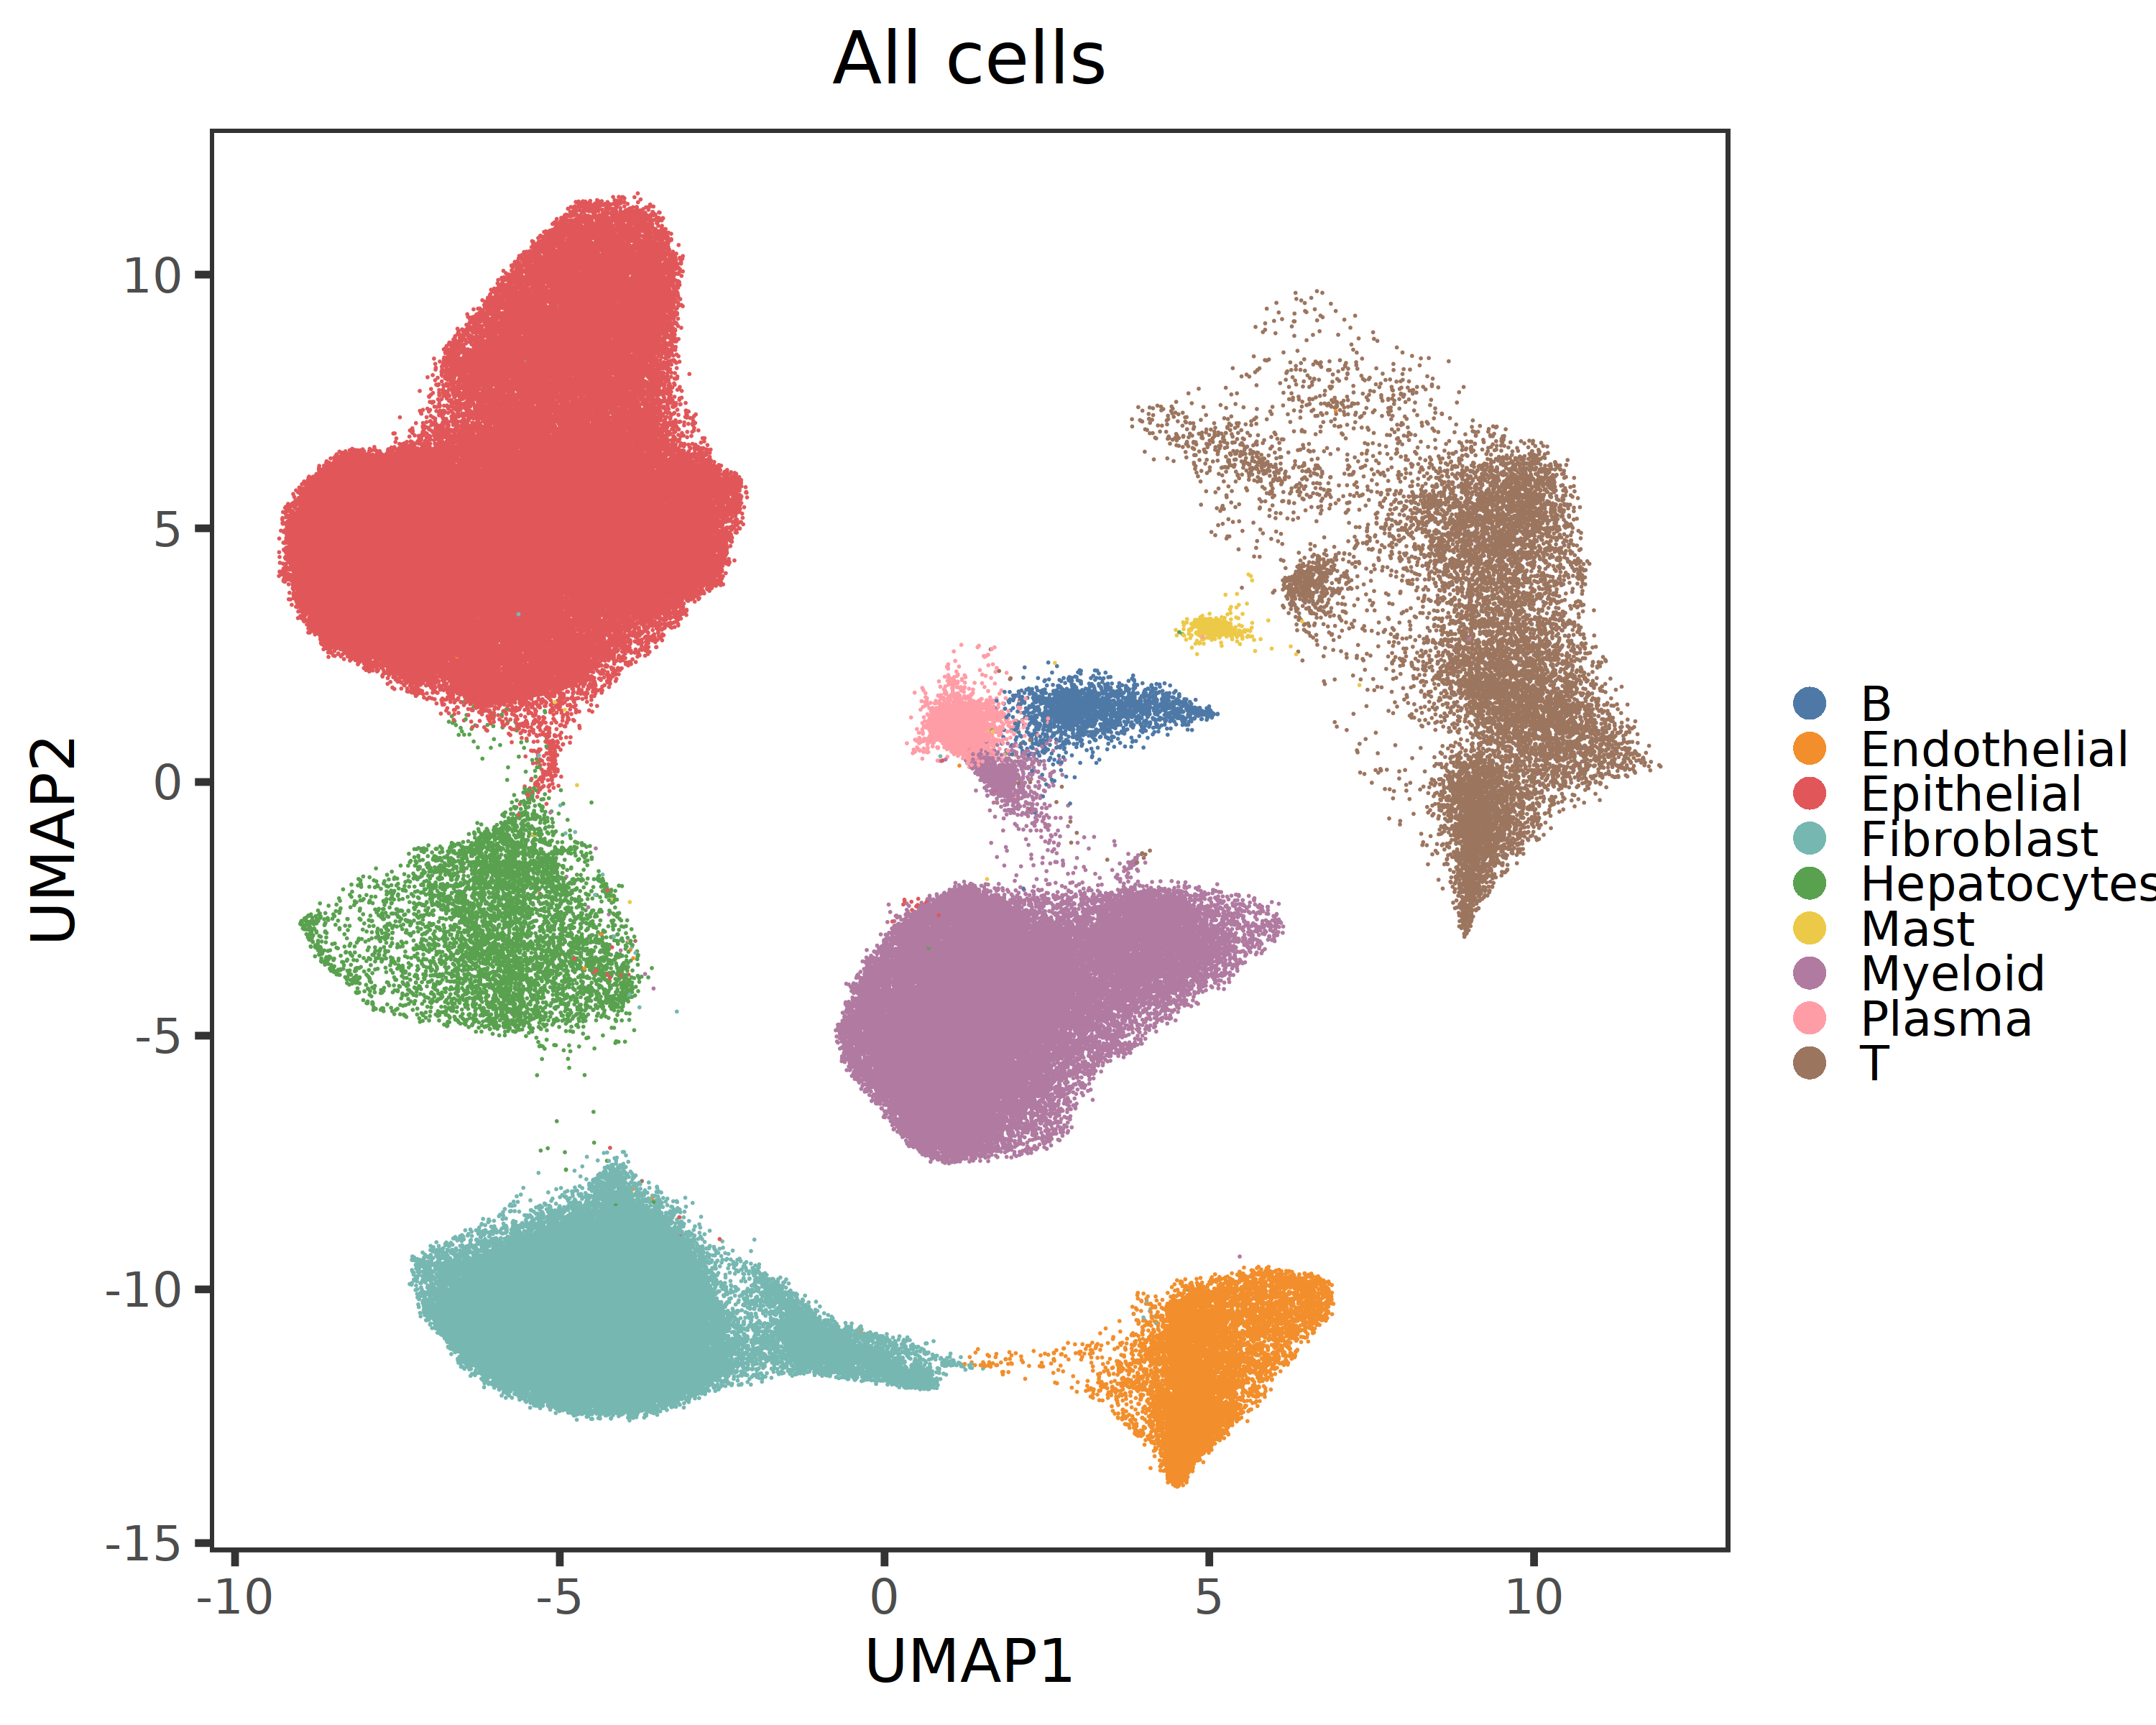

In [8]:
.metadata <- all_obj@meta.data %>% 
    tibble::rownames_to_column("cellid") %>% 
    filter(cellid %in% keep_cellids)
.embed <- all_obj@reductions$humap@cell.embeddings[.metadata$cellid, ]
p <- plot_scatter(
    .embed, .metadata, label_name = "celltype_level_1", point_size = 0.1,
    point_stroke=0.8, no_guides = FALSE, do_labels = FALSE, base_size = 50, legend_point_size=12) + 
    labs(x = "UMAP1", y = "UMAP2", title="All cells", color="") +
    theme(legend.key = element_blank())

fig.size(20, 25)
p

# Plot - Myeloid cells

In [9]:
.metadata %>% with(table(celltype_level_1))

celltype_level_1
          B Endothelial  Epithelial  Fibroblast Hepatocytes        Mast 
       1944        9046       95866       58934        6047         749 
    Myeloid      Plasma           T 
      42829        3135       12248 

In [10]:
mye_obj@meta.data %>% with(table(tech))

tech
   sc    xe 
38472 64449 

Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”


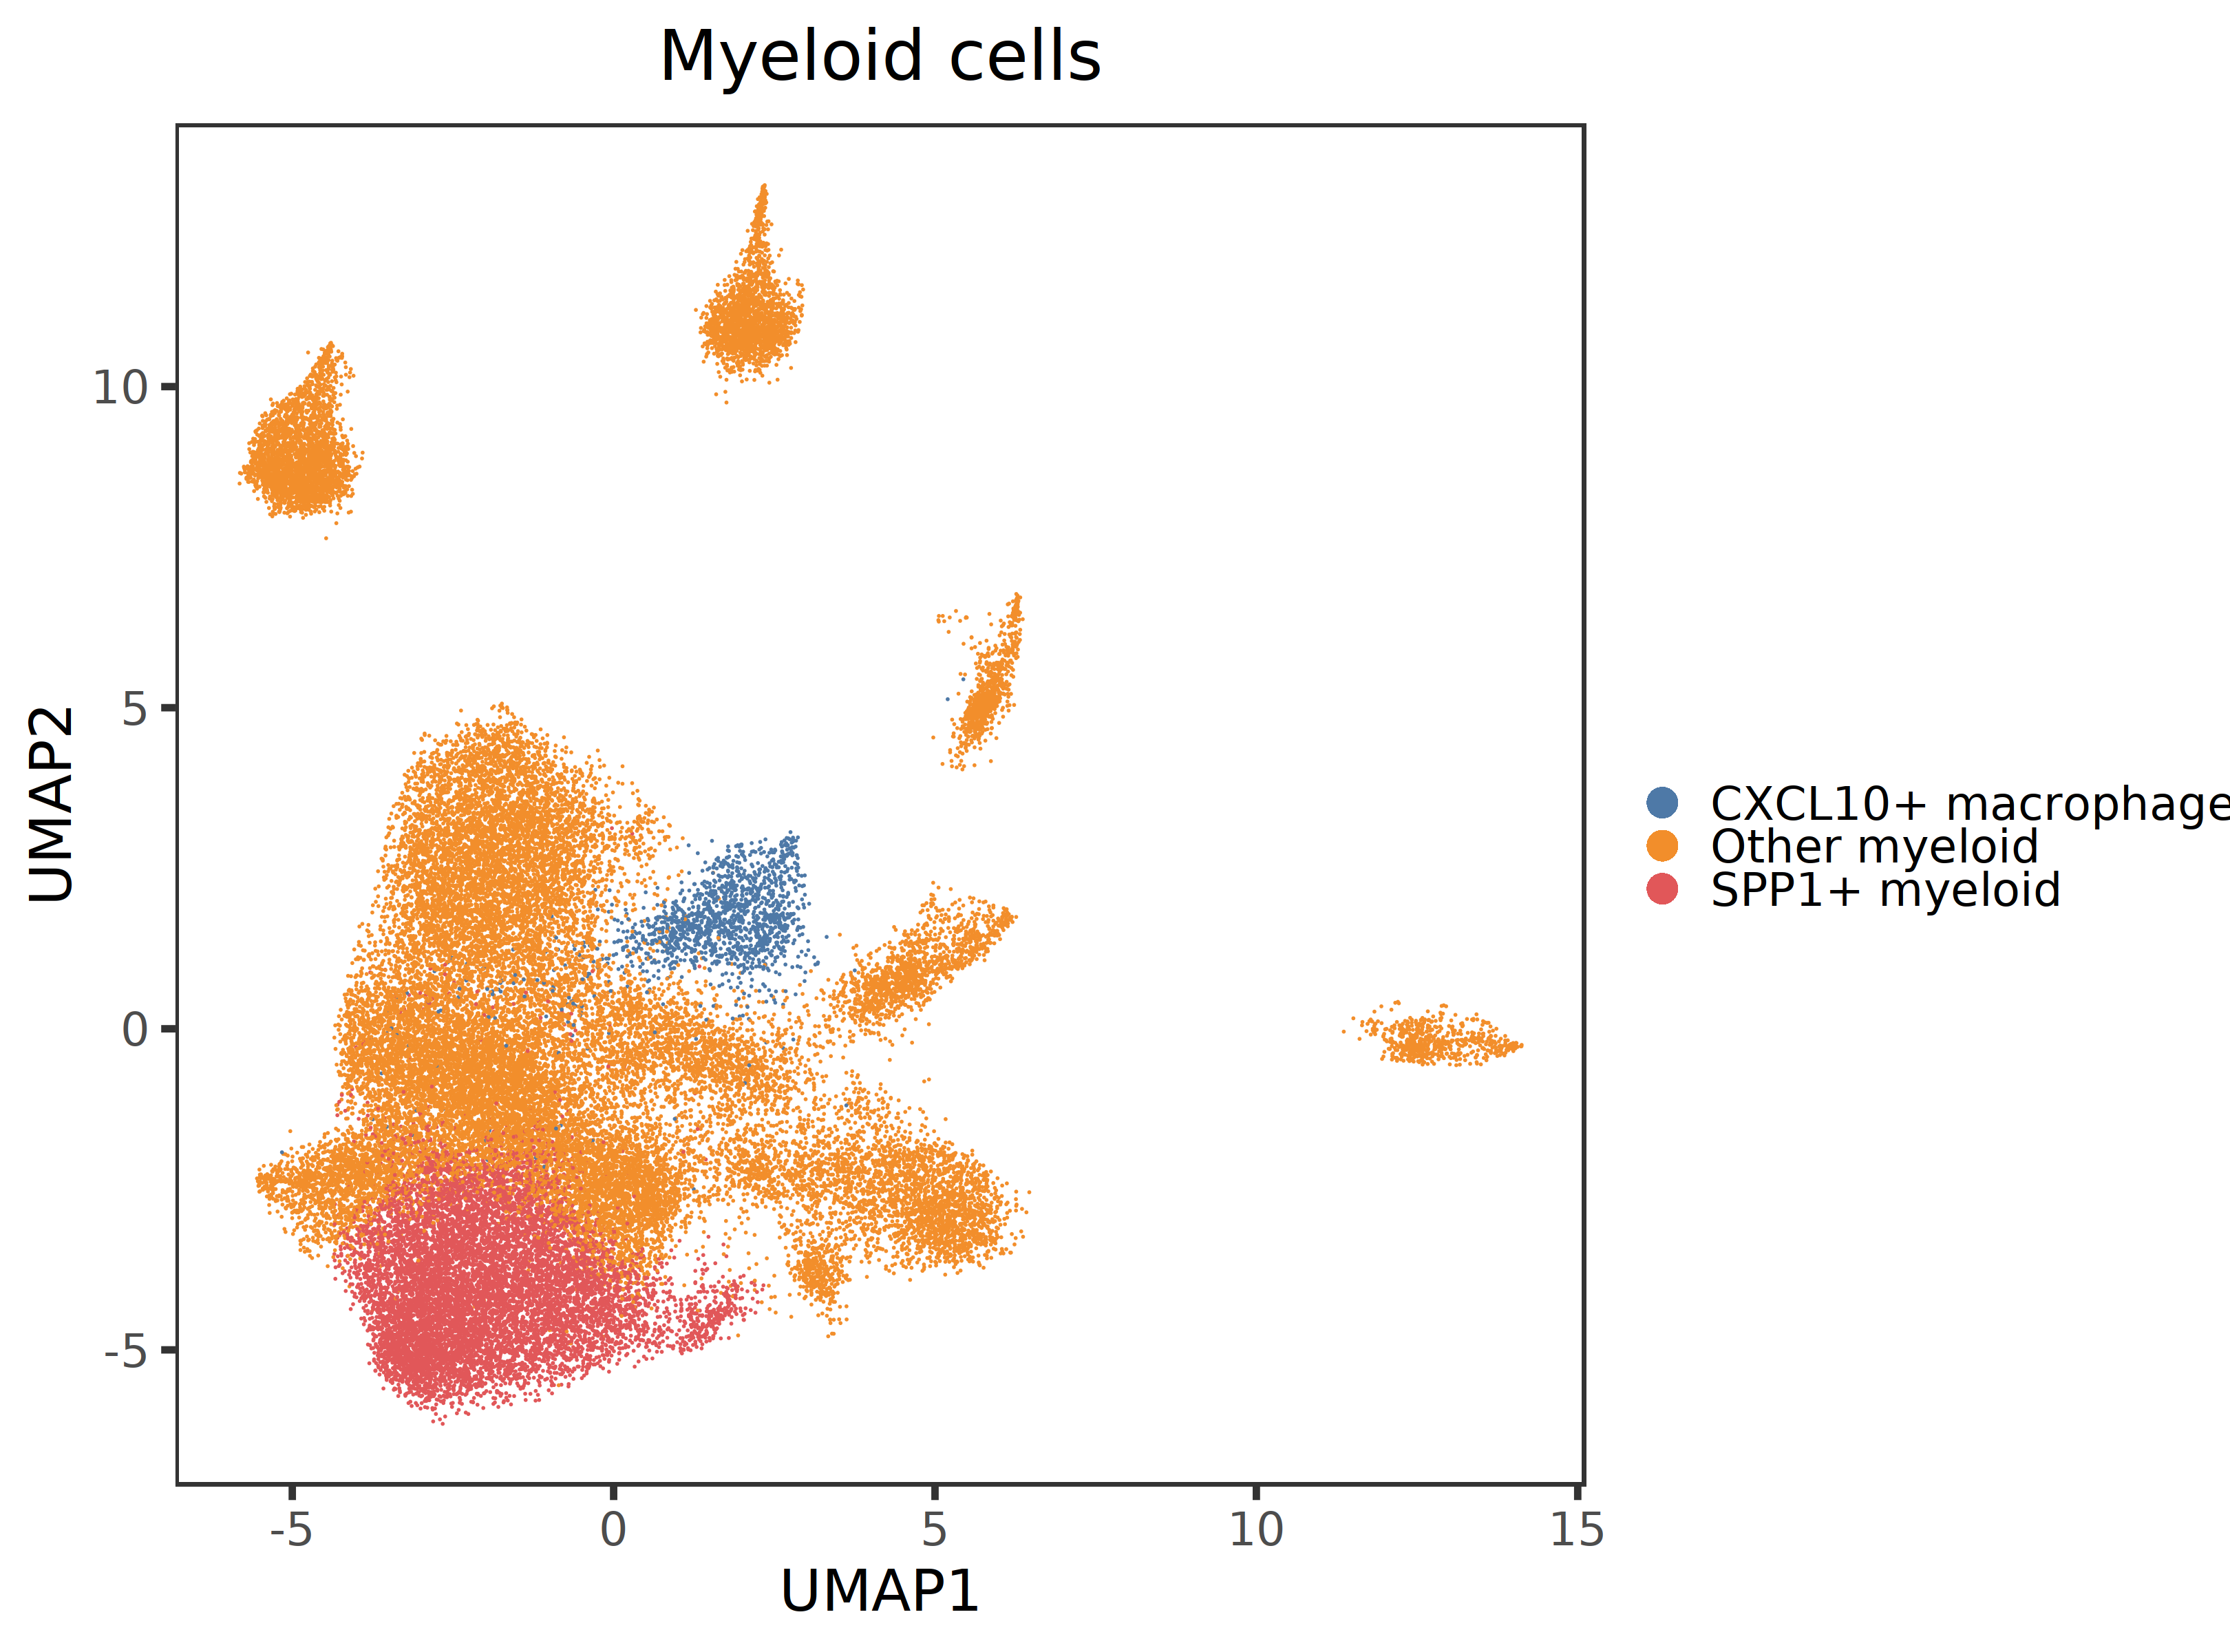

In [11]:
.metadata <- all_obj@meta.data %>% 
    tibble::rownames_to_column("cellid") %>% 
    filter(cellid %in% keep_cellids)  %>% 
    filter(celltype_level_1 == "Myeloid")

.metadata <- .metadata %>% 
    mutate(plot_celltype=case_when(
        celltype_finest_lvl=="CXCL10 mac_mye" ~ "CXCL10+ macrophages",
        celltype_finest_lvl=="SPP1 mye_mye" ~ "SPP1+ myeloid",
        .default="Other myeloid"))
.embed <- mye_obj@reductions$humap@cell.embeddings[.metadata$cellid, ]

p <- plot_scatter(
    .embed, .metadata, label_name = "plot_celltype", point_size = 0.1,
    point_stroke=0.8, no_guides = FALSE, do_labels = FALSE, base_size = 50, legend_point_size=12) + 
    labs(x = "UMAP1", y = "UMAP2", title="Myeloid cells", color="") +
    theme(legend.key = element_blank())

fig.size(20, 27)
p

# Plot - T cells

Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”


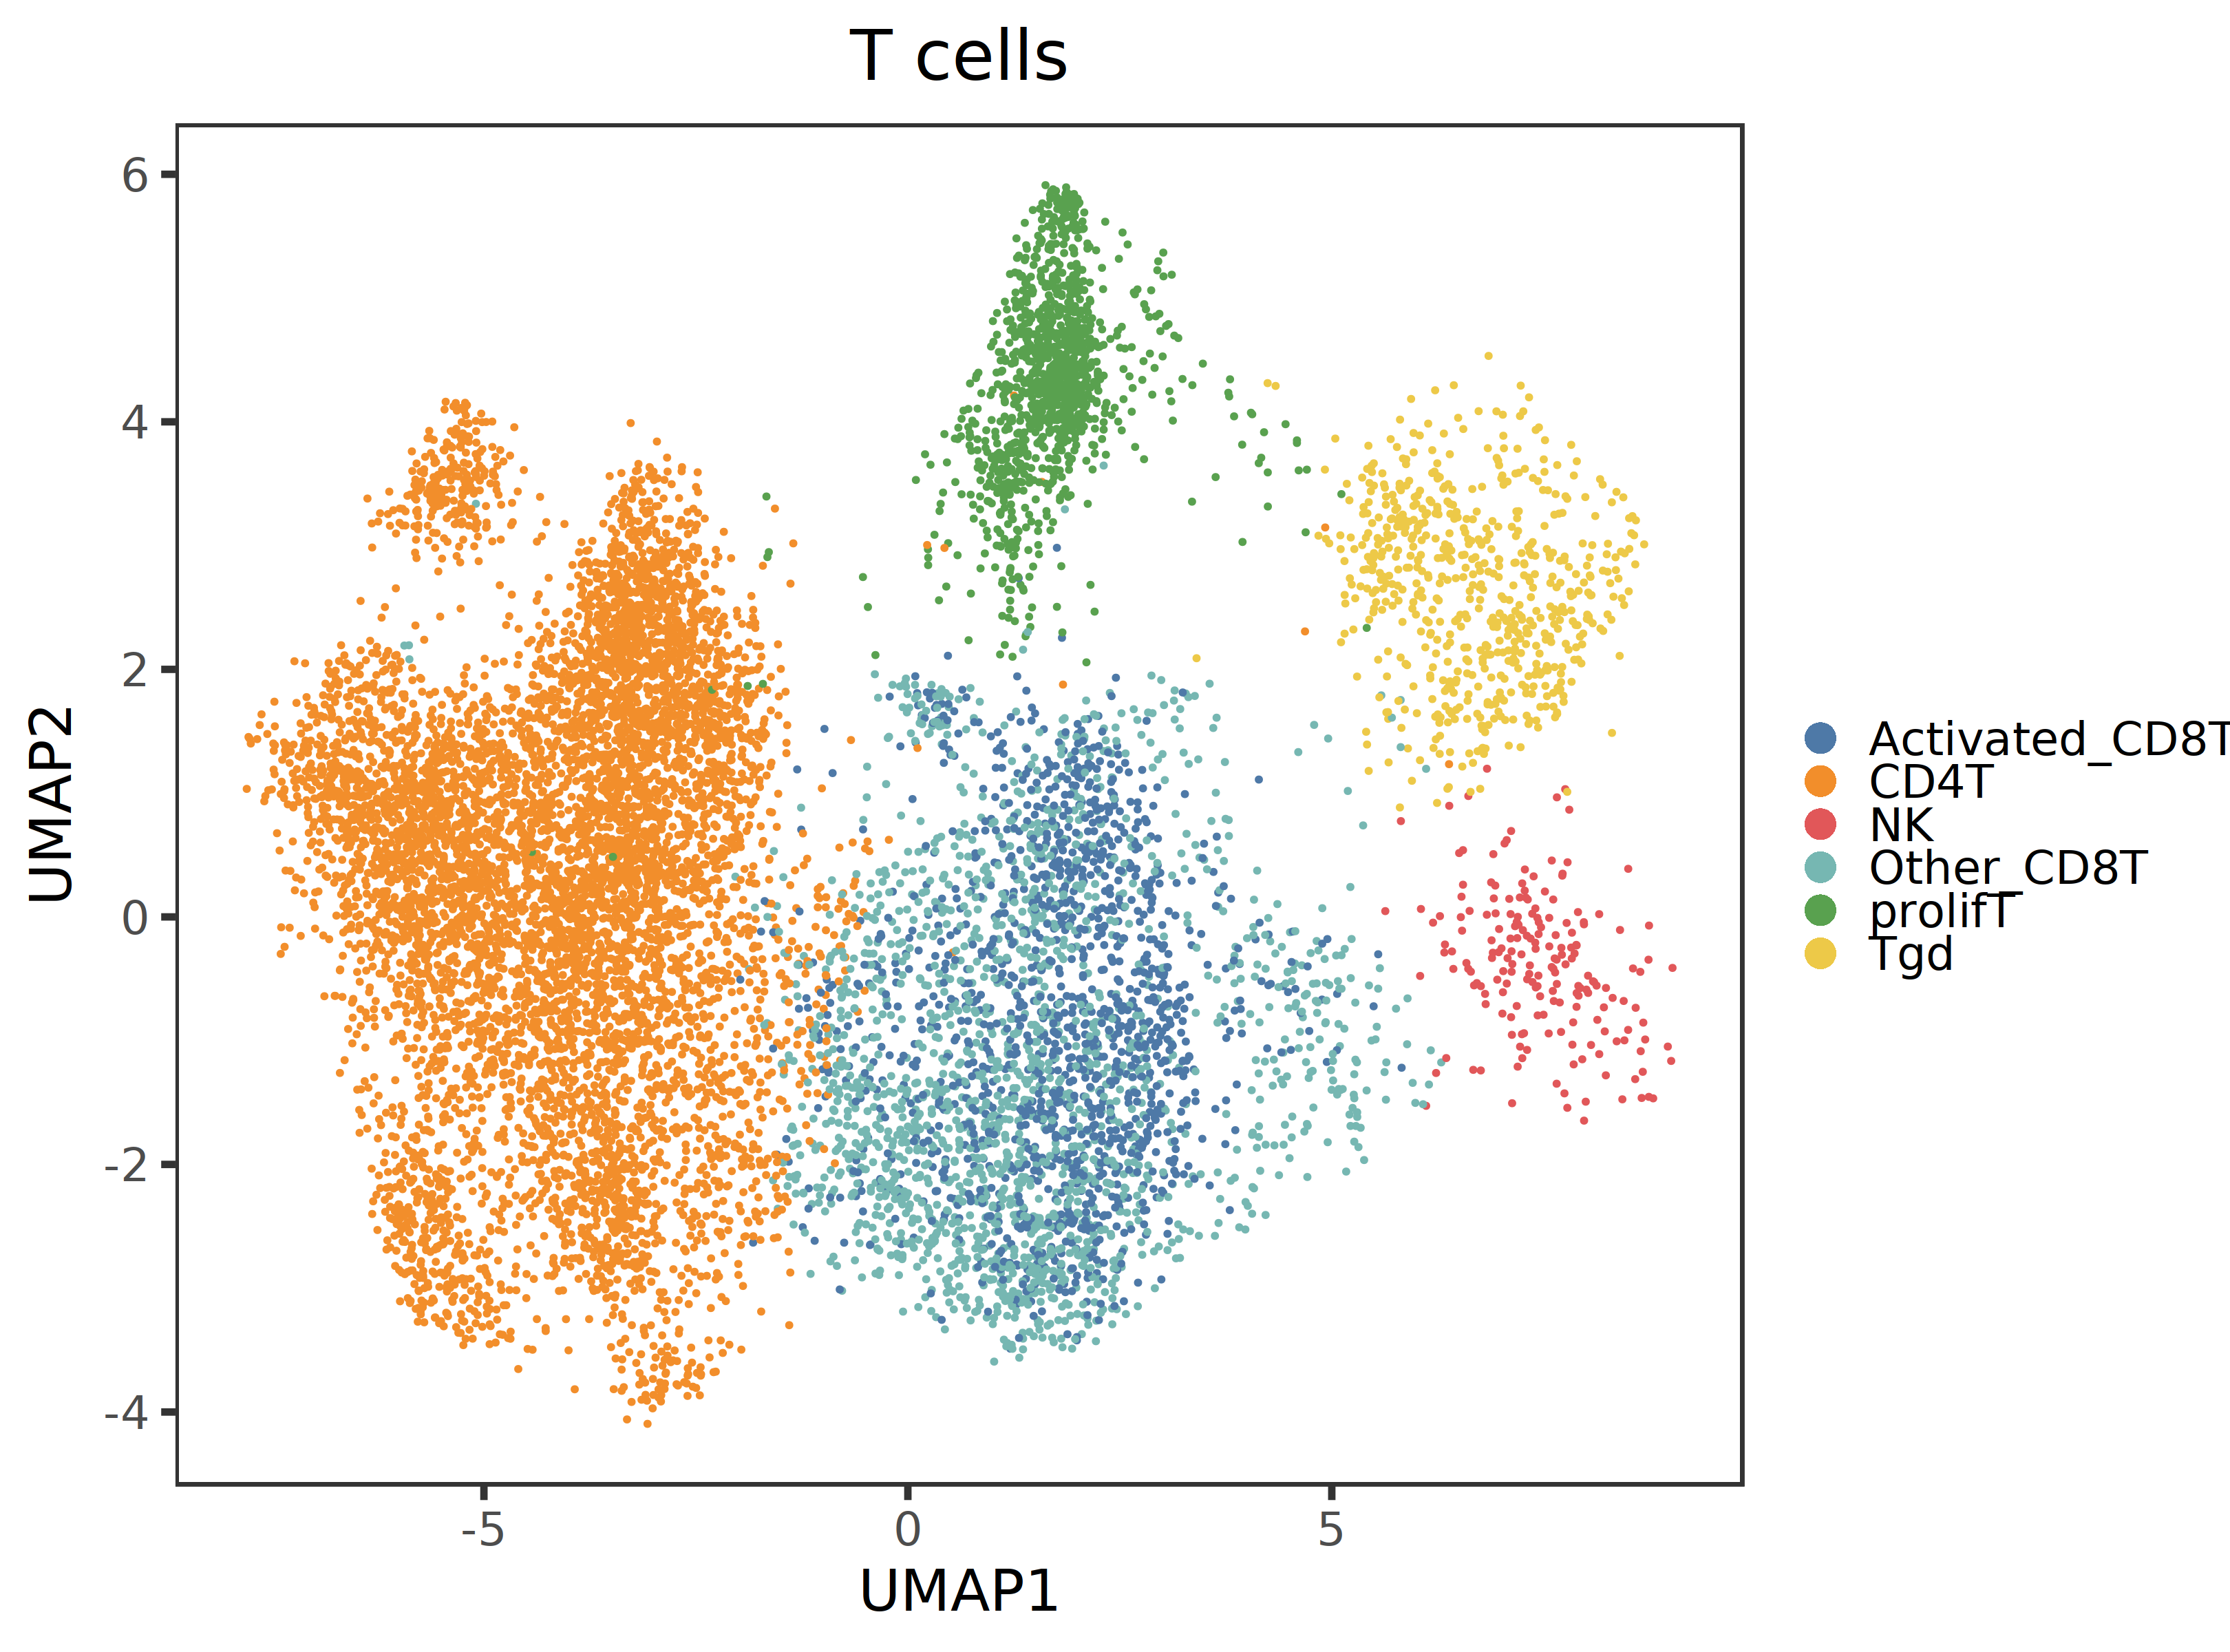

In [ ]:
mhcii_cd8t <- c("MHCII(ISGs)++_CD8T", "MHCII(ISGs)+_CD8T")
il7r_hobit_cd8t <- c("IL7R++ HOBIT_CD8T", "IL7R+ HOBIT_CD8T")
activated_cd8t <- c("Tex(CXCL13)_CD8T", "MHCII(ISGs)_CD8T", "TRM(HOBIT)_CD8T")
nk_like_cd8t <- c("FGFBP2 NK-like_CD8T") 
all_other_cd8t <- c("3_1_CD8T", "IL7R HOBIT_CD8T", "ISGs_CD8T", "Innate-like HOBIT_CD8T", "Other_CD8T")
treg <- c("Treg_CD4T")
cxcl13_isg_cd4t <- c("CXCL13_CD4T", "ISG15/IFI6_CD4T", "STAT1/GBP1_CD4T")
cd8_like_cd4t <- c("CD8T contam/quiescent_CD4T", "JUN/FOS+innate-like CD8_CD4T")
all_other_cd4t <- c("IL7R_CD4T", 'KLRB1/DUSP1_CD4T', 'PFN1_CD4T', 'Ribosomal_CD4T')

.metadata <- all_obj@meta.data %>% 
    tibble::rownames_to_column("cellid") %>% 
    filter(cellid %in% keep_cellids)  %>% 
    filter(celltype_level_1 == "T")

.metadata <- .metadata %>% 
    mutate(celltype_finest_lvl = if_else(celltype_finest_lvl %in% mhcii_cd8t, "MHCII(ISGs)_CD8T", celltype_finest_lvl)) %>% 
    mutate(celltype_finest_lvl = if_else(celltype_finest_lvl %in% il7r_hobit_cd8t, "IL7R HOBIT_CD8T", celltype_finest_lvl)) %>% 
    mutate(celltype_simplified=case_when(
        celltype_finest_lvl %in% activated_cd8t ~ "Activated_CD8T", 
        celltype_finest_lvl %in% nk_like_cd8t ~ "NK-like_CD8T", 
        celltype_finest_lvl %in% all_other_cd8t ~ "All_other_CD8T", 
        celltype_finest_lvl %in% treg ~ "Treg_CD4T", 
        celltype_finest_lvl %in% cxcl13_isg_cd4t ~ "CXCL13_ISG_CD4T", 
        celltype_finest_lvl %in% cd8_like_cd4t ~ "CD8_like_CD4T", 
        celltype_finest_lvl %in% all_other_cd4t ~ "All_other_CD4T", 
        .default = celltype_finest_lvl)) %>% 
    mutate(plot_celltype=case_when(
        celltype_simplified == "Activated_CD8T" ~ celltype_simplified,
        celltype_lvl_2 == "CD8T" & celltype_simplified != "Activated_CD8T" ~ "Other_CD8T",
        .default = celltype_lvl_2))

.embed <- t_obj@reductions$humap@cell.embeddings[.metadata$cellid, ]

p <- plot_scatter(
    .embed, .metadata, label_name = "plot_celltype", point_size = 1.5,
    point_stroke=1, no_guides = FALSE, do_labels = FALSE, base_size = 50, legend_point_size=12) + 
    labs(x = "UMAP1", y = "UMAP2", title="T cells", color="") +
    theme(legend.key = element_blank())

fig.size(20, 27)
p

In [13]:
sessionInfo()

R version 4.1.2 (2021-11-01)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Red Hat Enterprise Linux 9.7 (Plow)

Matrix products: default
BLAS/LAPACK: /home/hoy821/miniforge3/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] sf_1.0-7           SeuratObject_4.1.4 Seurat_4.4.0       ggthemes_4.2.4    
[5] ggplot2_4.0.1      dplyr_1.1.2       

loaded via a namespace (and not attached):
  [1] colorspace_2.1-0       Rtsne_0.17             deldir_1.0-9          
  [4] class_7.3-22           ellipsis_0.3.2         ggridg